# Modèle 2 — entraînement du Q-learning hybride et ablation

Implémente `docs/modele2.tex`. Le code est dans `src/` (testé par `uv run pytest`) ; ce notebook lance les expériences.

1. distribution exacte du croupier → $V_{STAND}$, référence exacte $Q^*_{HIT}$, $\pi^*$, $J(\pi)$ ;
2. entraînement du Q-learning **standard** et de l'**hybride** (avec $V_{STAND}$ exacte) sur 5 graines ;
3. analyse des états où les agents se trompent ;
4. **ablation** : hybride avec $\hat V_{STAND}$ estimée sur $n$ mains du croupier, à budget de simulations total égal ;
5. export `results/metrics.csv` et sauvegarde de la table.

Tables indexées `[p, d, a]` : total du joueur, carte visible du croupier (1 = as), as utilisable (0/1).

In [11]:
from pathlib import Path

import joblib
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.environment import HIT, STAND
from src.evaluate import J, J_STAR, PI_STAR, Q_STAR, REACH, V_TRUE, simulate
from src.q_learning import CONFIG, greedy_policy, train
from src.stand_value import OUTCOMES, empirical_dealer_probs, exact_dealer_probs, stand_table, tv_distance

Path("results").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
EXACT = exact_dealer_probs()
X = np.arange(1, CONFIG["episodes"] // CONFIG["eval_every"] + 1) * CONFIG["eval_every"]
CONFIG

{'episodes': 100000,
 'eps0': 1.0,
 'eps_min': 0.05,
 'decay': 0.99995,
 'gamma': 1.0,
 'eval_every': 2000,
 'seeds': [0, 1, 2, 3, 4]}

## 1. Référence exacte

Distribution du croupier par carte visible (ordre `OUTCOMES`), puis gain moyen exact de la politique optimale et de la baseline « tirer jusqu'à 17 ».

**Brancher le modèle 1 :** `stand_table({d: dealer_model.predict_proba([[d]])[0] for d in range(1, 11)})`, à condition que ses classes soient dans l'ordre `OUTCOMES`.

In [12]:
print(pd.DataFrame(EXACT, index=OUTCOMES).T.round(4))

pi_17 = np.zeros_like(PI_STAR)
pi_17[:17] = True
print(f"\nJ(pi*)         = {J_STAR:+.5f}")
print(f"J(tirer à <17) = {J(pi_17):+.5f}")

m, ci = simulate(PI_STAR, 100_000, seed=123)
print(f"pi* simulée sur 100 000 manches : {m:+.4f} ± {ci:.4f}")

        17      18      19      20      21    BUST
1   0.1308  0.1308  0.1308  0.1308  0.3616  0.1153
2   0.1398  0.1349  0.1297  0.1240  0.1180  0.3536
3   0.1350  0.1305  0.1256  0.1203  0.1147  0.3739
4   0.1305  0.1259  0.1214  0.1165  0.1112  0.3945
5   0.1223  0.1223  0.1177  0.1131  0.1082  0.4164
6   0.1654  0.1063  0.1063  0.1017  0.0972  0.4232
7   0.3686  0.1378  0.0786  0.0786  0.0741  0.2623
8   0.1286  0.3593  0.1286  0.0694  0.0694  0.2447
9   0.1200  0.1200  0.3508  0.1200  0.0608  0.2284
10  0.1114  0.1114  0.1114  0.3422  0.1114  0.2121

J(pi*)         = -0.04656
J(tirer à <17) = -0.07929
pi* simulée sur 100 000 manches : -0.0486 ± 0.0059


## 2. Entraînement : standard vs hybride ($V_{STAND}$ exacte)

standard 7.3 s / graine
hybrid 8.2 s / graine


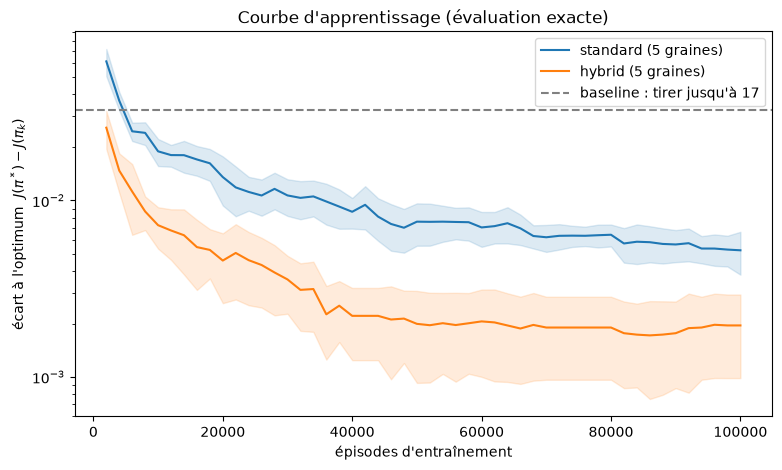

                J      gap    agree  max_q_err
standard -0.05177  0.00522  0.94929    0.25635
hybrid   -0.04851  0.00196  0.98357    0.23324


In [13]:
runs = {}
for agent in ("standard", "hybrid"):
    runs[agent] = [train(agent, seed) for seed in CONFIG["seeds"]]
    print(agent, f"{np.mean([r['seconds'] for r in runs[agent]]):.1f} s / graine")


def metrics(run):
    pi = greedy_policy(run["Q"])
    j = J(pi)
    return dict(J=j, gap=J_STAR - j, agree=(pi == PI_STAR)[REACH].mean(),
                max_q_err=np.abs(run["Q"][HIT] - Q_STAR)[REACH].max())


def band(ax, x, curves, label, **kw):
    gap = J_STAR - np.stack(curves)
    line, = ax.plot(x, gap.mean(0), label=label, **kw)
    ax.fill_between(x, gap.mean(0) - gap.std(0), gap.mean(0) + gap.std(0), color=line.get_color(), alpha=0.15)


fig, ax = plt.subplots(figsize=(9, 5))
for agent in runs:
    band(ax, X, [r["curve"] for r in runs[agent]], f"{agent} (5 graines)")
ax.axhline(J_STAR - J(pi_17), color="gray", ls="--", label="baseline : tirer jusqu'à 17")
ax.set(xlabel="épisodes d'entraînement", ylabel=r"écart à l'optimum  $J(\pi^*) - J(\pi_k)$",
       title="Courbe d'apprentissage (évaluation exacte)", yscale="log")
ax.legend()
fig.savefig("results/learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print(pd.DataFrame({a: pd.DataFrame([metrics(r) for r in rs]).mean() for a, rs in runs.items()}).T.round(5))

## 3. Où les agents se trompent-ils ?

$|Q^*_{HIT}(s) - V_{STAND}(s)|$ mesure à quel point la décision est tranchée en $s$. Si les erreurs se concentrent sur des états où cet écart est minuscule, elles coûtent peu.

In [14]:
delta = np.abs(Q_STAR - V_TRUE)
print(f"écart |Q* - V_STAND| médian sur les états atteignables : {np.median(delta[REACH]):.3f}\n")

for agent, rs in runs.items():
    wrong = np.stack([(greedy_policy(r["Q"]) != PI_STAR) & REACH for r in rs])
    d = np.broadcast_to(delta, wrong.shape)[wrong]
    print(f"{agent:9} : {wrong.sum(axis=(1, 2, 3)).mean():.1f} états faux en moyenne ; écart médian sur ces états {np.median(d):.3f}, "
          f"{(d < 0.02).mean():.0%} d'entre eux < 0,02")

wrong = np.mean([(greedy_policy(r["Q"]) != PI_STAR) & REACH for r in runs["hybrid"]], axis=0)
rows = [dict(p=p, d=d, a=a, graines_fausses=f"{wrong[p, d, a]:.0%}", optimal="HIT" if PI_STAR[p, d, a] else "STAND",
             ecart=delta[p, d, a]) for p, d, a in zip(*np.nonzero(wrong))]
print("\nHybride, états en désaccord avec pi* :")
print(pd.DataFrame(rows).sort_values("ecart").round(4).to_string(index=False))

écart |Q* - V_STAND| médian sur les états atteignables : 0.320

standard  : 14.2 états faux en moyenne ; écart médian sur ces états 0.063, 10% d'entre eux < 0,02
hybrid    : 4.6 états faux en moyenne ; écart médian sur ces états 0.039, 26% d'entre eux < 0,02

Hybride, états en désaccord avec pi* :
 p  d  a graines_fausses optimal  ecart
16 10  0             60%     HIT 0.0065
12  3  0             60%     HIT 0.0186
16  9  0             60%     HIT 0.0338
18  1  1             40%     HIT 0.0393
12  2  0             20%     HIT 0.0394
15 10  0             40%     HIT 0.0396
18 10  1             40%     HIT 0.0404
16  7  0             20%     HIT 0.0606
15  9  0             40%     HIT 0.0716
18  9  1             20%     HIT 0.0824
15  8  0             20%     HIT 0.0937
17  4  1             20%     HIT 0.1399
17  2  1             20%     HIT 0.1525


## 4. Ablation : qualité du modèle 1 et budget total

On remplace la distribution exacte par les fréquences observées sur $n$ mains du croupier simulées (carte visible tirée au hasard, comme le dataset du modèle 1). C'est ce qu'apprendrait un classifieur parfaitement calibré à partir d'une seule variable.

Pour une comparaison équitable, l'axe horizontal compte **toutes** les simulations : $n$ mains du croupier + épisodes d'entraînement. L'hybride à distribution exacte est tracé sans coût, comme borne idéale.

In [15]:
NS = [100, 1_000, 10_000, 100_000]
ablation = {}
for n in NS:
    ablation[n] = []
    for seed in CONFIG["seeds"]:
        probs = empirical_dealer_probs(n, np.random.default_rng(10_000 + seed))
        run = train("hybrid", seed, V=stand_table(probs))
        run["tv"] = tv_distance(probs, EXACT)
        ablation[n].append(run)
    print(f"n = {n:>7} : epsilon_TV moyen = {np.mean([r['tv'] for r in ablation[n]]):.4f}")

n =     100 : epsilon_TV moyen = 0.5504
n =    1000 : epsilon_TV moyen = 0.1526
n =   10000 : epsilon_TV moyen = 0.0452
n =  100000 : epsilon_TV moyen = 0.0154


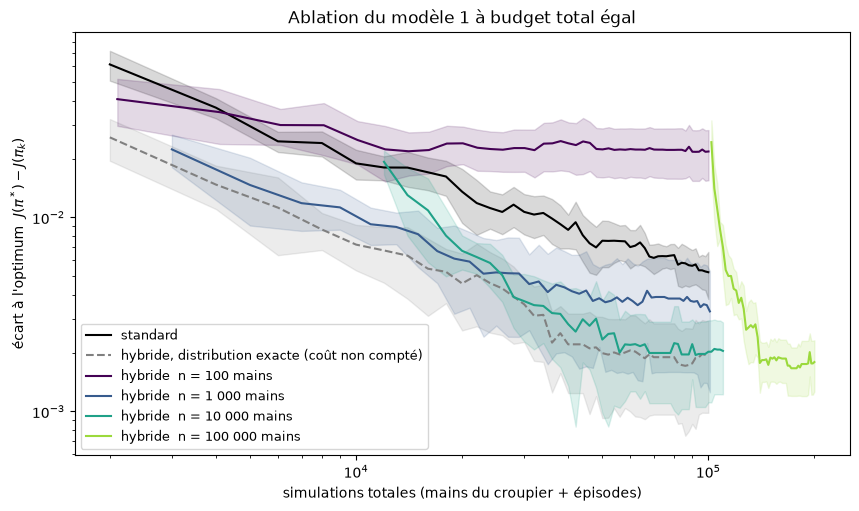

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5))
band(ax, X, [r["curve"] for r in runs["standard"]], "standard", color="black")
band(ax, X, [r["curve"] for r in runs["hybrid"]], "hybride, distribution exacte (coût non compté)", color="gray", ls="--")
for n, color in zip(NS, plt.cm.viridis(np.linspace(0, 0.85, len(NS)))):
    band(ax, X + n, [r["curve"] for r in ablation[n]], f"hybride, n = {n:,} mains".replace(",", " "), color=color)
ax.set(xscale="log", yscale="log", xlabel="simulations totales (mains du croupier + épisodes)",
       ylabel=r"écart à l'optimum  $J(\pi^*) - J(\pi_k)$", title="Ablation du modèle 1 à budget total égal")
ax.legend(fontsize=9)
fig.savefig("results/ablation.png", dpi=150, bbox_inches="tight")
plt.show()

Comparaison à **100 000 simulations au total**. Pour l'hybride, on prend le dernier point d'évaluation qui tient dans le budget ($100\,000 - n$ épisodes, arrondi vers le bas à un multiple de 2 000), ce qui le désavantage légèrement. La borne $\eta = 2\varepsilon_{TV}$ vient du lemme 4.

In [17]:
BUDGET = 100_000


def gap_at(run, episodes):
    i = episodes // CONFIG["eval_every"] - 1
    return J_STAR - run["curve"][i] if i >= 0 else np.nan


rows = [dict(methode="standard", n=0, eps_TV=0.0,
             gap_budget=np.mean([gap_at(r, BUDGET) for r in runs["standard"]]),
             gap_final=np.mean([metrics(r)["gap"] for r in runs["standard"]]))]
rows.append(dict(methode="hybride exact (gratuit)", n=0, eps_TV=0.0,
                 gap_budget=np.mean([gap_at(r, BUDGET) for r in runs["hybrid"]]),
                 gap_final=np.mean([metrics(r)["gap"] for r in runs["hybrid"]])))
for n in NS:
    rows.append(dict(methode="hybride estimé", n=n, eps_TV=np.mean([r["tv"] for r in ablation[n]]),
                     gap_budget=np.mean([gap_at(r, BUDGET - n) for r in ablation[n]]),
                     gap_final=np.mean([metrics(r)["gap"] for r in ablation[n]])))
summary = pd.DataFrame(rows)
summary["eta"] = 2 * summary["eps_TV"]
print(summary.round(5).to_string(index=False))

                methode      n  eps_TV  gap_budget  gap_final     eta
               standard      0 0.00000     0.00522    0.00522 0.00000
hybride exact (gratuit)      0 0.00000     0.00196    0.00196 0.00000
         hybride estimé    100 0.55039     0.02178    0.02186 1.10078
         hybride estimé   1000 0.15261     0.00353    0.00328 0.30522
         hybride estimé  10000 0.04522     0.00203    0.00205 0.09044
         hybride estimé 100000 0.01538         NaN    0.00180 0.03077


## 5. Export des métriques et sauvegarde

In [18]:
records = []
for agent, rs in runs.items():
    for seed, r in zip(CONFIG["seeds"], rs):
        records.append(dict(methode=agent, n_dealer=0 if agent == "hybrid" else np.nan, seed=seed, tv=0.0 if agent == "hybrid" else np.nan,
                            episodes=CONFIG["episodes"], seconds=r["seconds"], **metrics(r)))
for n, rs in ablation.items():
    for seed, r in zip(CONFIG["seeds"], rs):
        records.append(dict(methode="hybrid_estimated", n_dealer=n, seed=seed, tv=r["tv"],
                            episodes=CONFIG["episodes"], seconds=r["seconds"], **metrics(r)))
pd.DataFrame(records).to_csv("results/metrics.csv", index=False)

best = runs["hybrid"][0]
payload = dict(q_hit=best["Q"][HIT], visits=best["N"][HIT], seed=CONFIG["seeds"][0], config=CONFIG,
               dealer_probs="exact (récurrence f(h, u))", gymnasium_version=gym.__version__)
joblib.dump(payload, "models/q_hit_table.pkl")
assert np.array_equal(joblib.load("models/q_hit_table.pkl")["q_hit"], payload["q_hit"])
print(f"{len(records)} lignes dans results/metrics.csv ; table sauvegardée dans models/q_hit_table.pkl")

30 lignes dans results/metrics.csv ; table sauvegardée dans models/q_hit_table.pkl
